# Multi-region prompts with Florence-2

<a href="https://colab.research.google.com/github/anyantudre/Florence-2-Vision-Language-Model/blob/main/5.%20Multi-region%20prompts%20with%20Florence-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Florence-2's region tasks (`<REGION_TO_DESCRIPTION>`, `<REGION_TO_CATEGORY>`, `<REGION_TO_OCR>`, `<REGION_TO_SEGMENTATION>`) take one box per prompt. To ask about many boxes in the same image, build one prompt per box and send them all in a single batched `generate` call.

This notebook detects objects, then describes every detected region in one call. It also shows how to pass your own boxes, and checks that batching gives the same answers as running the boxes one by one.

In [ ]:
!pip install -q -U transformers

In [2]:
import re
import time

import requests
import torch
from IPython.display import display
from PIL import Image, ImageDraw
from transformers import AutoProcessor, Florence2ForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

model_id = "florence-community/Florence-2-large"
model = Florence2ForConditionalGeneration.from_pretrained(model_id, dtype=dtype).to(device).eval()
processor = AutoProcessor.from_pretrained(model_id)

## Helpers

Florence-2 writes boxes as four location tokens, `<loc_x1><loc_y1><loc_x2><loc_y2>`, on a 1000 × 1000 grid. `box_to_loc` converts a box in pixels to those tokens, with the same rounding the processor uses.

`run` sends a list of prompts for one image as a single batch. Batched outputs end with `<pad>` tokens, so `clean` removes them, along with the location tokens that region tasks repeat at the end of their answer.

In [3]:
def box_to_loc(box, image_size):
    """Convert a pixel box (x1, y1, x2, y2) to Florence-2 location tokens."""
    width, height = image_size
    sizes = (width, height, width, height)
    bins = [min(int(value // (size / 1000)), 999) for value, size in zip(box, sizes)]
    return "".join(f"<loc_{b}>" for b in bins)


def clean(text):
    """Remove padding, start/end and location tokens from a text answer."""
    return re.sub(r"<loc_\d+>|<pad>|</?s>", "", text).strip()


def run(task, image, extra_inputs=("",), num_beams=3, max_new_tokens=256):
    """Run one task on one image for several extra inputs, in a single batch."""
    prompts = [task + extra for extra in extra_inputs]
    inputs = processor(text=prompts, images=[image] * len(prompts), return_tensors="pt", padding=True)
    inputs = inputs.to(device, dtype)
    with torch.inference_mode():
        generated_ids = model.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=num_beams, do_sample=False)
    texts = processor.batch_decode(generated_ids, skip_special_tokens=False)
    return [processor.post_process_generation(t, task=task, image_size=image.size)[task] for t in texts]


def describe_regions(image, boxes, task="<REGION_TO_DESCRIPTION>", batch_size=16, **kwargs):
    """Answer a region task for every box, `batch_size` boxes per generate call."""
    answers = []
    for start in range(0, len(boxes), batch_size):
        chunk = boxes[start:start + batch_size]
        locs = [box_to_loc(box, image.size) for box in chunk]
        answers += [clean(a) for a in run(task, image, locs, **kwargs)]
    return answers

## Detect objects

In [4]:
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")

detections = run("<OD>", image)[0]
detections

{'bboxes': [[6, 54, 317, 474],
  [345, 24, 639, 371],
  [40, 73, 175, 117],
  [333, 77, 370, 186],
  [0, 0, 639, 476]],
 'labels': ['cat', 'cat', 'remote control', 'remote control', 'studio couch']}

## Describe every region in one call

All boxes go into one batch. `batch_size` caps how many prompts run at once, which keeps memory in check when there are many boxes.

In [5]:
descriptions = describe_regions(image, detections["bboxes"])

for label, box, description in zip(detections["labels"], detections["bboxes"], descriptions):
    print(f"{label:15} {str([round(v) for v in box]):22} {description}")

cat             [6, 54, 317, 474]      A tabby cat sleeping on a pink blanket with a remote control.
cat             [345, 24, 639, 371]    brown tabby cat sleeping on pink blanket
remote control  [40, 73, 175, 117]     remote control
remote control  [333, 77, 370, 186]    remote control
studio couch    [0, 0, 639, 476]       cats sleeping on pink couch with remote controls


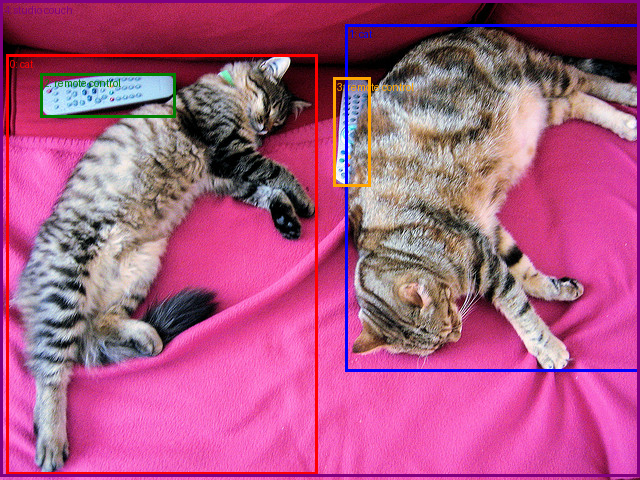

In [6]:
def draw_regions(image, boxes, texts):
    canvas = image.copy()
    draw = ImageDraw.Draw(canvas)
    colors = ["red", "blue", "green", "orange", "purple", "cyan", "magenta", "yellow"]
    for i, (box, text) in enumerate(zip(boxes, texts)):
        color = colors[i % len(colors)]
        draw.rectangle(box, outline=color, width=3)
        draw.text((box[0] + 4, box[1] + 4), f"{i}: {text}", fill=color)
    display(canvas)


draw_regions(image, detections["bboxes"], detections["labels"])

## Other region tasks

The same helper works for `<REGION_TO_CATEGORY>` and `<REGION_TO_OCR>`. `<REGION_TO_OCR>` only makes sense on regions that contain text: on the regions below, which have none, it returns meaningless strings.

In [7]:
categories = describe_regions(image, detections["bboxes"], task="<REGION_TO_CATEGORY>")
ocr = describe_regions(image, detections["bboxes"], task="<REGION_TO_OCR>")

for label, category, text in zip(detections["labels"], categories, ocr):
    print(f"{label:15} category: {category:15} OCR: {text}")

cat             category: cat             OCR: 2
cat             category: cat             OCR: A
remote control  category: remote control  OCR: 00000
remote control  category: remote control  OCR: 1
studio couch    category: studio couch    OCR: 2


## Your own boxes

Boxes can come from anywhere: another detector, a labelling tool, or a user's clicks. Pass them in pixels, as `(x1, y1, x2, y2)`.

In [8]:
my_boxes = [
    (0, 0, 320, 480),    # left half
    (320, 0, 640, 480),  # right half
    (40, 70, 180, 120),  # around the first remote
]
for box, description in zip(my_boxes, describe_regions(image, my_boxes)):
    print(box, "->", description)

(0, 0, 320, 480) -> A tabby cat sleeping on a pink blanket with a remote control.
(320, 0, 640, 480) -> A tabby cat sleeping on a pink blanket with a remote control.
(40, 70, 180, 120) -> remote control


## Batch versus one by one

Batching changes the speed, not the answers. The cell below runs each task both ways and compares the results. It runs everything once first to warm up the GPU, so the timings are fair.

In [9]:
def timed(fn):
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    result = fn()
    if device == "cuda":
        torch.cuda.synchronize()
    return result, time.perf_counter() - start


boxes = detections["bboxes"]
describe_regions(image, boxes)  # warm-up

for task in ("<REGION_TO_DESCRIPTION>", "<REGION_TO_CATEGORY>"):
    one_by_one, t_single = timed(lambda: [describe_regions(image, [b], task=task)[0] for b in boxes])
    batched, t_batch = timed(lambda: describe_regions(image, boxes, task=task))
    print(f"{task:25} same answers: {one_by_one == batched}   one by one: {t_single:.2f}s   batched: {t_batch:.2f}s")

<REGION_TO_DESCRIPTION>   same answers: True   one by one: 2.26s   batched: 1.00s


<REGION_TO_CATEGORY>      same answers: True   one by one: 1.48s   batched: 0.81s


## Notes

- The batch holds one copy of the image per box, so the vision encoder runs once per box. Memory grows with the number of boxes; lower `batch_size` if you run out of GPU memory.
- On the laptop GPU (RTX 4070) used for the saved outputs, batching five boxes was 1.6 to 2.3× faster than running them one by one, depending on the run. The gain depends on your GPU and on how many boxes fit in one batch.
- The check above compares batched and one-by-one answers. Rerun it on your own images if exact matches matter for your use case.